# CNN+LSTM v2 GradientSHAP Analysis
# Input:  CNN_LSTM_results_v2/cnn_lstm_v2_best.pt
#         CNN_LSTM_results_v2/sensor_stats.csv
#         explainability_figures/tft_v3_interpretation_results.json
#         traffic_features_v3.parquet
# Output: explainability_figures/cnn_lstm_shap_results.json
#         explainability_figures/ (4 figures)

In [1]:
import os
import json
import time
import warnings
warnings.filterwarnings("ignore")

import duckdb
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── SHAP ───────────────────────────────────────────────────────────────────────
# captum is PyTorch's native attribution library
# GradientSHAP is implemented in captum.attr
try:
    from captum.attr import GradientShap
    print("captum imported successfully")
except ImportError:
    print("captum not found — installing...")
    os.system("pip install captum --quiet")
    from captum.attr import GradientShap
    print("captum installed and imported")

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nDevice: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    torch.set_float32_matmul_precision("medium")

# ── Paths ──────────────────────────────────────────────────────────────────────
FEATURES_PATH = "/home/iai-labor/traffic_project/traffic_features_v3.parquet"
CNN_RESULTS   = "/home/iai-labor/traffic_project/CNN_LSTM_results_v2"
CNN_CHECKPOINT= "/home/iai-labor/traffic_project/CNN_LSTM_results_v2/cnn_lstm_v2_best.pt"
FIGURES_DIR   = "/home/iai-labor/traffic_project/explainability_figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

SUBCLASS_NAMES  = {0: "URB_normal", 1: "URB_ramp", 2: "M30", 3: "C30"}
SUBCLASS_COLORS = {
    "URB_normal": "#1565C0",
    "URB_ramp":   "#F57C00",
    "M30":        "#2E7D32",
    "C30":        "#C62828",
}

# ── Verify checkpoint ──────────────────────────────────────────────────────────
assert os.path.exists(CNN_CHECKPOINT), \
    f"Checkpoint not found: {CNN_CHECKPOINT}"
print(f"\nCheckpoint confirmed: {CNN_CHECKPOINT}")
print(f"Size: {os.path.getsize(CNN_CHECKPOINT)/1e6:.1f} MB")

# ── Load CNN+LSTM config ───────────────────────────────────────────────────────
with open(os.path.join(CNN_RESULTS, "cnn_lstm_v2_config.json")) as f:
    cnn_saved = json.load(f)

CFG          = cnn_saved["config"]
FEATURE_COLS = cnn_saved["feature_cols"]
N_FEATURES   = cnn_saved["n_features"]

print(f"\nCNN+LSTM v2 config:")
print(f"  encoder:    {CFG['max_encoder_length']}h")
print(f"  prediction: {CFG['max_prediction_length']}h")
print(f"  n_features: {N_FEATURES}")
print(f"  dropout:    {CFG['dropout']}")
print(f"  best_val:   {cnn_saved['best_val_loss']:.4f}")
print(f"  epochs:     {cnn_saved['epochs_run']}")

captum imported successfully

Device: cuda
GPU: NVIDIA RTX A2000 12GB

Checkpoint confirmed: /home/iai-labor/traffic_project/CNN_LSTM_results_v2/cnn_lstm_v2_best.pt
Size: 1.0 MB

CNN+LSTM v2 config:
  encoder:    48h
  prediction: 6h
  n_features: 29
  dropout:    0.1
  best_val:   0.1460
  epochs:     44


In [2]:
# ── Load SENSOR_STATS ──────────────────────────────────────────────────────────
SENSOR_STATS = pd.read_csv(
    os.path.join(CNN_RESULTS, "sensor_stats.csv"),
    index_col="SENSOR_ID"
)
print(f"SENSOR_STATS loaded: {len(SENSOR_STATS)} sensors")
print(f"μ range: {SENSOR_STATS['mu'].min():.1f} – "
      f"{SENSOR_STATS['mu'].max():.1f} veh/h")

# ── Sensor selection — identical to training ───────────────────────────────────
con = duckdb.connect()

sampled = con.sql(f"""
    WITH ranked AS (
        SELECT SENSOR_ID, road_subclass_enc, COUNT(*) AS n_obs,
               ROW_NUMBER() OVER (
                   PARTITION BY road_subclass_enc
                   ORDER BY COUNT(*) DESC, SENSOR_ID ASC
               ) AS rn
        FROM read_parquet('{FEATURES_PATH}')
        WHERE split    = 'train'
          AND target   IS NOT NULL
          AND lag_1h   IS NOT NULL
          AND lag_168h IS NOT NULL
        GROUP BY SENSOR_ID, road_subclass_enc
        HAVING COUNT(*) > 8760
    )
    SELECT SENSOR_ID, road_subclass_enc, n_obs
    FROM ranked
    WHERE rn <= {CFG['sensors_per_class']}
    ORDER BY road_subclass_enc, SENSOR_ID
""").df()

SENSOR_IDS = sampled["SENSOR_ID"].tolist()
id_list    = ",".join(map(str, SENSOR_IDS))
print(f"Sensors: {len(SENSOR_IDS)} ({CFG['sensors_per_class']} per sub-class)")

# ── Load data ──────────────────────────────────────────────────────────────────
print("Loading data...")
t0 = time.time()

df = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, target, road_subclass_enc, split,
           longitude, latitude, is_main_artery,
           dist_station_km, dist_stadium_km, dist_hospital_km,
           dist_university_km, dist_mall_km, dist_bus_station_km,
           near_major_poi,
           hour_sin, hour_cos, dow_sin, dow_cos,
           month_sin, month_cos,
           is_weekend, is_holiday, is_rush_hour, season,
           lag_1h, lag_2h, lag_3h, lag_24h, lag_168h,
           roll_mean_3h, roll_mean_24h
    FROM read_parquet('{FEATURES_PATH}')
    WHERE SENSOR_ID IN ({id_list})
      AND target IS NOT NULL
      AND lag_1h IS NOT NULL
    ORDER BY SENSOR_ID, DATETIME
""").df()

df["DATETIME"]   = pd.to_datetime(df["DATETIME"])
df               = df.sort_values(
    ["SENSOR_ID","DATETIME"]
).reset_index(drop=True)
df["sensor_str"] = df["SENSOR_ID"].astype(str)
print(f"Loaded: {len(df):,} rows in {time.time()-t0:.1f}s")

# ── Time index ─────────────────────────────────────────────────────────────────
time_origin    = df["DATETIME"].min()
df["time_idx"] = (
    (df["DATETIME"] - time_origin)
    .dt.total_seconds().div(3600).round().astype(int)
)
train_end_idx = int(
    (pd.Timestamp(CFG["train_end"]) - time_origin).total_seconds() / 3600
)
val_end_idx = int(
    (pd.Timestamp(CFG["val_end"]) - time_origin).total_seconds() / 3600
)
BUFFER = CFG["max_encoder_length"]  # 48h

print(f"train_end_idx={train_end_idx} | val_end_idx={val_end_idx}")

# ── Normalisation — identical to training ──────────────────────────────────────
df["mu_i"]    = df["SENSOR_ID"].map(SENSOR_STATS["mu"])
df["sigma_i"] = df["SENSOR_ID"].map(SENSOR_STATS["sigma"])

TARGET_COLS = [
    "target","lag_1h","lag_2h","lag_3h",
    "lag_24h","lag_168h","roll_mean_3h","roll_mean_24h"
]
NORM_COLS = [
    "target_norm","lag_1h_norm","lag_2h_norm","lag_3h_norm",
    "lag_24h_norm","lag_168h_norm","roll_mean_3h_norm","roll_mean_24h_norm"
]
for raw_col, norm_col in zip(TARGET_COLS, NORM_COLS):
    df[norm_col] = (df[raw_col] - df["mu_i"]) / df["sigma_i"]

# ── Test split ─────────────────────────────────────────────────────────────────
static_cols  = [
    "longitude","latitude","is_main_artery",
    "dist_station_km","dist_stadium_km","dist_hospital_km",
    "dist_university_km","dist_mall_km","dist_bus_station_km",
    "near_major_poi",
]
lag_cols_raw = [
    "lag_1h","lag_2h","lag_3h","lag_24h","lag_168h",
    "roll_mean_3h","roll_mean_24h",
]

df_test = df[df["time_idx"] > val_end_idx - BUFFER].copy()

for col in static_cols:
    if df_test[col].isna().any():
        fill_val = float(df[col].median())
        df_test[col] = df_test[col].fillna(fill_val)

df_test = df_test.dropna(
    subset=lag_cols_raw
).reset_index(drop=True)

print(f"Test rows: {len(df_test):,}")

# ── Sensor → sub-class lookup ──────────────────────────────────────────────────
sensor_to_class = (
    df.drop_duplicates("sensor_str")
      .set_index("sensor_str")["road_subclass_enc"]
      .astype(int).to_dict()
)
class_to_sensors = {enc: [] for enc in range(4)}
for sid, enc in sensor_to_class.items():
    class_to_sensors[enc].append(sid)

print("\nSub-class sensor counts:")
for enc, name in SUBCLASS_NAMES.items():
    print(f"  {name}: {len(class_to_sensors[enc])} sensors")

SENSOR_STATS loaded: 200 sensors
μ range: 28.6 – 3924.1 veh/h
Sensors: 200 (50 per sub-class)
Loading data...
Loaded: 5,981,000 rows in 5.0s
train_end_idx=21167 | val_end_idx=25559
Test rows: 878,600

Sub-class sensor counts:
  URB_normal: 50 sensors
  URB_ramp: 50 sensors
  M30: 50 sensors
  C30: 50 sensors


In [3]:
# ── CNN+LSTM model definition — must match training exactly ───────────────────
class CNNLSTMForecaster(nn.Module):
    def __init__(self, n_features, pred_len, cfg):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(
                in_channels  = n_features,
                out_channels = cfg["cnn_filters"],
                kernel_size  = cfg["cnn_kernel"],
                padding      = cfg["cnn_kernel"] // 2,
            ),
            nn.BatchNorm1d(cfg["cnn_filters"]),
            nn.ReLU(),
            nn.Dropout(cfg["dropout"]),
        )
        self.lstm = nn.LSTM(
            input_size  = cfg["cnn_filters"],
            hidden_size = cfg["lstm_hidden"],
            num_layers  = cfg["lstm_layers"],
            batch_first = True,
            dropout     = cfg["dropout"] if cfg["lstm_layers"] > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Dropout(cfg["dropout"]),
            nn.Linear(cfg["lstm_hidden"], 64),
            nn.ReLU(),
            nn.Linear(64, pred_len),
        )

    def forward(self, x):
        # x: (batch, seq_len, n_features)
        x = x.permute(0, 2, 1)      # (batch, n_features, seq_len)
        x = self.cnn(x)              # (batch, cnn_filters, seq_len)
        x = x.permute(0, 2, 1)      # (batch, seq_len, cnn_filters)
        _, (h_n, _) = self.lstm(x)  # h_n: (n_layers, batch, hidden)
        x = h_n[-1]                  # (batch, hidden)
        return self.head(x)          # (batch, pred_len)

# ── Load checkpoint ────────────────────────────────────────────────────────────
print("Loading CNN+LSTM v2 checkpoint...")
t0 = time.time()

model = CNNLSTMForecaster(
    n_features = N_FEATURES,
    pred_len   = CFG["max_prediction_length"],
    cfg        = CFG,
).to(device)

model.load_state_dict(
    torch.load(CNN_CHECKPOINT, map_location=device)
)
model.eval()

total_params = sum(p.numel() for p in model.parameters())
print(f"Model loaded in {time.time()-t0:.1f}s")
print(f"Parameters: {total_params:,}")
print(f"Device: {next(model.parameters()).device}")

# ── Verify forward pass ────────────────────────────────────────────────────────
dummy = torch.zeros(
    1, CFG["max_encoder_length"], N_FEATURES
).to(device)
with torch.no_grad():
    dummy_out = model(dummy)
print(f"\nForward pass check:")
print(f"  Input:  {tuple(dummy.shape)}")
print(f"  Output: {tuple(dummy_out.shape)}")
assert dummy_out.shape == (1, CFG["max_prediction_length"]), \
    f"Output shape mismatch: {dummy_out.shape}"
print(f"✓ Model architecture confirmed")

Loading CNN+LSTM v2 checkpoint...
Model loaded in 0.1s
Parameters: 245,830
Device: cuda:0

Forward pass check:
  Input:  (1, 48, 29)
  Output: (1, 6)
✓ Model architecture confirmed


In [4]:
# ── Dataset class — identical to evaluation notebook ──────────────────────────
class ForecastDataset(Dataset):
    def __init__(self, df_split, encoder_len, pred_len,
                 feature_cols, min_pred_idx=None):
        self.windows    = []
        self.sensor_ids = []
        self.t_starts   = []
        enc     = encoder_len
        pred    = pred_len
        sensors = df_split["sensor_str"].unique()

        for sid in sensors:
            sdf = df_split[
                df_split["sensor_str"] == sid
            ].sort_values("time_idx").reset_index(drop=True)

            if len(sdf) < enc + pred:
                continue

            feats   = sdf[feature_cols].values.astype(np.float32)
            targets = sdf["target_norm"].values.astype(np.float32)
            t_idxs  = sdf["time_idx"].values

            for i in range(len(sdf) - enc - pred + 1):
                decoder_start = int(t_idxs[i + enc])
                if min_pred_idx is not None:
                    if decoder_start < min_pred_idx:
                        continue
                X = feats[i: i + enc]
                y = targets[i + enc: i + enc + pred]
                self.windows.append((X, y))
                self.sensor_ids.append(sid)
                self.t_starts.append(decoder_start)

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        X, y = self.windows[idx]
        return (
            torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32),
        )

# ── Stratified sample for SHAP ─────────────────────────────────────────────────
# importance estimates. GradientSHAP needs two sets:
#
# BACKGROUND set: reference distribution that represents "typical" input.
#   GradientSHAP uses this to compute the baseline against which
#   attributions are measured. Too few = noisy estimates.
#   Too many = slow computation. 50 per sub-class = 200 total.
# 
#
# TEST set: windows whose predictions we want to explain.
#   These are the windows for which SHAP values are computed.
#   25 per sub-class = 100 total.

N_BG   = 25   # background windows per sub-class
N_TEST = 25   # test windows per sub-class
np.random.seed(42)

# Middle of test period — avoids boundary effects
mid_test = (val_end_idx + df["time_idx"].max()) // 2
window   = 24 * 7  # one week

# ── Select sensors ─────────────────────────────────────────────────────────────
bg_sensors   = []
test_sensors = []

for enc in range(4):
    sensors_in_class = class_to_sensors[enc]
    # Background sensors — first half of available sensors
    bg_chosen = np.random.choice(
        sensors_in_class,
        size    = min(N_BG, len(sensors_in_class)),
        replace = False
    ).tolist()
    # Test sensors — second half (different from background)
    remaining = [s for s in sensors_in_class if s not in bg_chosen]
    test_chosen = np.random.choice(
        remaining,
        size    = min(N_TEST, len(remaining)),
        replace = False
    ).tolist()
    bg_sensors.extend(bg_chosen)
    test_sensors.extend(test_chosen)

print(f"Background sensors: {len(bg_sensors)} "
      f"({N_BG} per sub-class)")
print(f"Test sensors:       {len(test_sensors)} "
      f"({N_TEST} per sub-class)")

# ── Build background dataset ───────────────────────────────────────────────────
df_bg = df_test[
    df_test["sensor_str"].isin(bg_sensors) &
    (df_test["time_idx"] >= mid_test - window) &
    (df_test["time_idx"] <= mid_test + window)
].copy()

bg_dataset = ForecastDataset(
    df_bg,
    encoder_len  = CFG["max_encoder_length"],
    pred_len     = CFG["max_prediction_length"],
    feature_cols = FEATURE_COLS,
    min_pred_idx = val_end_idx + 1,
)

# ── Build test dataset ─────────────────────────────────────────────────────────
df_shap = df_test[
    df_test["sensor_str"].isin(test_sensors) &
    (df_test["time_idx"] >= mid_test - window) &
    (df_test["time_idx"] <= mid_test + window)
].copy()

shap_dataset = ForecastDataset(
    df_shap,
    encoder_len  = CFG["max_encoder_length"],
    pred_len     = CFG["max_prediction_length"],
    feature_cols = FEATURE_COLS,
    min_pred_idx = val_end_idx + 1,
)

print(f"\nBackground windows: {len(bg_dataset):,}")
print(f"SHAP test windows:  {len(shap_dataset):,}")

# ── Convert to tensors for GradientSHAP ───────────────────────────────────────
# GradientSHAP works directly on tensors — no DataLoader needed
# Load all windows into GPU memory at once (small enough)

bg_X   = torch.stack([bg_dataset[i][0]   for i in range(len(bg_dataset))]).to(device)
shap_X = torch.stack([shap_dataset[i][0] for i in range(len(shap_dataset))]).to(device)

# Track sensor IDs for per-subclass analysis
shap_sensor_ids = [shap_dataset.sensor_ids[i]
                   for i in range(len(shap_dataset))]

print(f"\nBackground tensor:  {tuple(bg_X.shape)}")
print(f"SHAP input tensor:  {tuple(shap_X.shape)}")
print(f"  (windows × encoder_steps × features)")
print(f"✓ Tensors ready for GradientSHAP")

# ── Human-readable feature labels ─────────────────────────────────────────────
LABEL_MAP = {
    "road_subclass_enc":    "Road sub-class",
    "longitude":            "Longitude",
    "latitude":             "Latitude",
    "is_main_artery":       "Main artery",
    "dist_station_km":      "Dist. railway station",
    "dist_stadium_km":      "Dist. stadium",
    "dist_hospital_km":     "Dist. hospital",
    "dist_university_km":   "Dist. university",
    "dist_mall_km":         "Dist. shopping mall",
    "dist_bus_station_km":  "Dist. bus station",
    "near_major_poi":       "Near major POI",
    "hour_sin":             "Hour (sin)",
    "hour_cos":             "Hour (cos)",
    "dow_sin":              "Day of week (sin)",
    "dow_cos":              "Day of week (cos)",
    "month_sin":            "Month (sin)",
    "month_cos":            "Month (cos)",
    "is_weekend":           "Is weekend",
    "is_holiday":           "Is holiday",
    "is_rush_hour":         "Is rush hour",
    "season":               "Season",
    "lag_1h_norm":          "Lag 1h",
    "lag_2h_norm":          "Lag 2h",
    "lag_3h_norm":          "Lag 3h",
    "lag_24h_norm":         "Lag 24h",
    "lag_168h_norm":        "Lag 168h (weekly)",
    "roll_mean_3h_norm":    "Rolling mean 3h",
    "roll_mean_24h_norm":   "Rolling mean 24h",
    "target_norm":          "Traffic intensity (lag)",
}

FEATURE_LABELS = [LABEL_MAP.get(f, f) for f in FEATURE_COLS]

print(f"\nFeature labels ({len(FEATURE_LABELS)}):")
for i, (col, label) in enumerate(zip(FEATURE_COLS, FEATURE_LABELS)):
    print(f"  [{i:2d}] {col:<25} → {label}")

Background sensors: 100 (25 per sub-class)
Test sensors:       100 (25 per sub-class)

Background windows: 28,116
SHAP test windows:  28,400

Background tensor:  (28116, 48, 29)
SHAP input tensor:  (28400, 48, 29)
  (windows × encoder_steps × features)
✓ Tensors ready for GradientSHAP

Feature labels (29):
  [ 0] road_subclass_enc         → Road sub-class
  [ 1] longitude                 → Longitude
  [ 2] latitude                  → Latitude
  [ 3] is_main_artery            → Main artery
  [ 4] dist_station_km           → Dist. railway station
  [ 5] dist_stadium_km           → Dist. stadium
  [ 6] dist_hospital_km          → Dist. hospital
  [ 7] dist_university_km        → Dist. university
  [ 8] dist_mall_km              → Dist. shopping mall
  [ 9] dist_bus_station_km       → Dist. bus station
  [10] near_major_poi            → Near major POI
  [11] hour_sin                  → Hour (sin)
  [12] hour_cos                  → Hour (cos)
  [13] dow_sin                   → Day of week (

In [5]:
# ── GradientSHAP wrapper for MIMO output ──────────────────────────────────────
class MeanOutputWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)
        return out.mean(dim=1, keepdim=True)  # (batch, 1)

# ── Fix: cuDNN RNN backward requires train() mode ─────────────────────────────
# GradientSHAP needs gradients through the LSTM.
# cuDNN's RNN implementation only supports backward in train() mode.
# We set train() mode but disable dropout manually by setting p=0
# on all Dropout layers so stochasticity does not affect attributions.

def disable_dropout(model):
    """Set all Dropout layers to p=0 — keeps train() mode for
    cuDNN RNN backward while removing stochastic dropout effect."""
    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.p = 0.0

model.train()             # required for cuDNN RNN backward
disable_dropout(model)    # remove dropout stochasticity
wrapped_model = MeanOutputWrapper(model).to(device)

# Verify wrapper
with torch.enable_grad():
    test_out = wrapped_model(shap_X[:2])
print(f"Wrapped model output shape: {tuple(test_out.shape)}")
print(f"  (expected (2, 1)) ✓")

# ── GradientSHAP ──────────────────────────────────────────────────────────────
# GradientSHAP algorithm:
# For each test input x and random baseline x' from background:
#   Attribution = gradient(output w.r.t. interpolated input) × (x - x')
# Averaged over n_samples interpolations.
#
# n_samples=50: standard value from Captum documentation
# stdevs=0.0: background distribution provides variance — no extra noise needed

print("\nInitialising GradientSHAP...")
explainer = GradientShap(wrapped_model)

SHAP_BATCH = 64
N_SAMPLES  = 50

print(f"Running GradientSHAP:")
print(f"  Test windows:  {len(shap_X):,}")
print(f"  Batch size:    {SHAP_BATCH}")
print(f"  Noise samples: {N_SAMPLES}")
print(f"  Total batches: {len(shap_X) // SHAP_BATCH + 1}")
print(f"  Expected time: 5–15 minutes...")

t0         = time.time()
shap_attrs = []

for batch_start in range(0, len(shap_X), SHAP_BATCH):
    batch_end   = min(batch_start + SHAP_BATCH, len(shap_X))
    batch_input = shap_X[batch_start:batch_end].requires_grad_(True)

    # Random baselines from background distribution
    bg_indices = torch.randint(0, len(bg_X),
                               (batch_end - batch_start,))
    batch_bg   = bg_X[bg_indices]

    attrs = explainer.attribute(
        inputs    = batch_input,
        baselines = batch_bg,
        n_samples = N_SAMPLES,
        stdevs    = 0.0,
    )

    shap_attrs.append(attrs.detach().cpu().numpy())

    if (batch_start // SHAP_BATCH + 1) % 25 == 0:
        elapsed = (time.time() - t0) / 60
        print(f"  Batch {batch_start//SHAP_BATCH+1:>3} | "
              f"{batch_end:,}/{len(shap_X):,} windows | "
              f"{elapsed:.1f} min")

shap_attrs = np.concatenate(shap_attrs, axis=0)
elapsed    = (time.time() - t0) / 60

print(f"\nGradientSHAP complete in {elapsed:.1f} min")
print(f"Attribution shape: {shap_attrs.shape}")
print(f"  (windows × encoder_steps × features)")

# ── Aggregate across timesteps ─────────────────────────────────────────────────
# Mean absolute value across 48 encoder timesteps.

shap_per_window = np.abs(shap_attrs).mean(axis=1)  # (n_windows, 29)
shap_mean       = shap_per_window.mean(axis=0)      # (29,)
shap_norm       = shap_mean / shap_mean.sum()       # normalised

print(f"\nAfter temporal aggregation: {shap_per_window.shape}")
print(f"\nOverall SHAP importance (normalised, top 10):")
top_idx = np.argsort(shap_norm)[::-1]
for rank, i in enumerate(top_idx[:10]):
    print(f"  [{rank+1:2d}] {FEATURE_LABELS[i]:<30} {shap_norm[i]:.4f}")

Wrapped model output shape: (2, 1)
  (expected (2, 1)) ✓

Initialising GradientSHAP...
Running GradientSHAP:
  Test windows:  28,400
  Batch size:    64
  Noise samples: 50
  Total batches: 444
  Expected time: 5–15 minutes...
  Batch  25 | 1,600/28,400 windows | 0.1 min
  Batch  50 | 3,200/28,400 windows | 0.1 min
  Batch  75 | 4,800/28,400 windows | 0.2 min
  Batch 100 | 6,400/28,400 windows | 0.2 min
  Batch 125 | 8,000/28,400 windows | 0.3 min
  Batch 150 | 9,600/28,400 windows | 0.3 min
  Batch 175 | 11,200/28,400 windows | 0.4 min
  Batch 200 | 12,800/28,400 windows | 0.4 min
  Batch 225 | 14,400/28,400 windows | 0.5 min
  Batch 250 | 16,000/28,400 windows | 0.5 min
  Batch 275 | 17,600/28,400 windows | 0.6 min
  Batch 300 | 19,200/28,400 windows | 0.6 min
  Batch 325 | 20,800/28,400 windows | 0.7 min
  Batch 350 | 22,400/28,400 windows | 0.7 min
  Batch 375 | 24,000/28,400 windows | 0.8 min
  Batch 400 | 25,600/28,400 windows | 0.8 min
  Batch 425 | 27,200/28,400 windows | 0.9 m

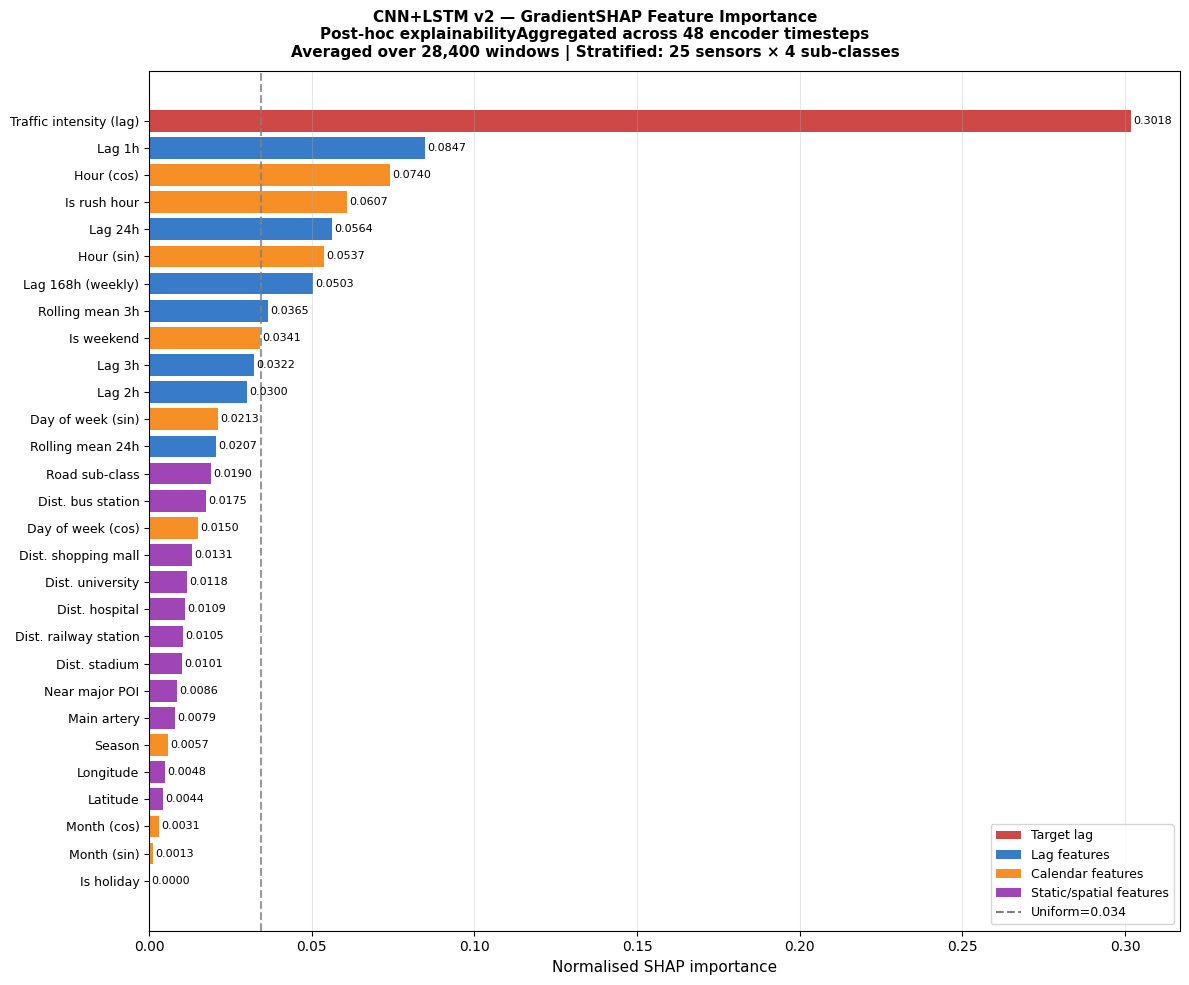

Saved: /home/iai-labor/traffic_project/explainability_figures/cnn_lstm_shap_overall.png

Full SHAP importance ranking (all 29 features):
Rank  Feature                            SHAP   vs uniform           Group
---------------------------------------------------------------------------
1     Traffic intensity (lag)          0.3018       8.75x      Target lag
2     Lag 1h                           0.0847       2.46x             Lag
3     Hour (cos)                       0.0740       2.15x        Calendar
4     Is rush hour                     0.0607       1.76x        Calendar
5     Lag 24h                          0.0564       1.63x             Lag
6     Hour (sin)                       0.0537       1.56x        Calendar
7     Lag 168h (weekly)                0.0503       1.46x             Lag
8     Rolling mean 3h                  0.0365       1.06x             Lag
9     Is weekend                       0.0341       0.99x        Calendar
10    Lag 3h                           0.0322 

In [6]:
# ── Overall SHAP importance bar chart ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 10))
fig.suptitle(
    "CNN+LSTM v2 — GradientSHAP Feature Importance\n"
    "Post-hoc explainability"
    "Aggregated across 48 encoder timesteps\n"
    f"Averaged over {len(shap_X):,} windows | "
    "Stratified: 25 sensors × 4 sub-classes",
    fontsize=11, fontweight="bold"
)

order   = np.argsort(shap_norm)   # ascending for horizontal bar
labels  = [FEATURE_LABELS[i] for i in order]
values  = shap_norm[order]
uniform = 1.0 / N_FEATURES

# Colour by feature group
FEATURE_GROUPS = {
    "Road sub-class":          "#8E24AA",  # purple — static
    "Longitude":               "#8E24AA",
    "Latitude":                "#8E24AA",
    "Main artery":             "#8E24AA",
    "Dist. railway station":   "#8E24AA",
    "Dist. stadium":           "#8E24AA",
    "Dist. hospital":          "#8E24AA",
    "Dist. university":        "#8E24AA",
    "Dist. shopping mall":     "#8E24AA",
    "Dist. bus station":       "#8E24AA",
    "Near major POI":          "#8E24AA",
    "Hour (sin)":              "#F57C00",  # orange — calendar
    "Hour (cos)":              "#F57C00",
    "Day of week (sin)":       "#F57C00",
    "Day of week (cos)":       "#F57C00",
    "Month (sin)":             "#F57C00",
    "Month (cos)":             "#F57C00",
    "Is weekend":              "#F57C00",
    "Is holiday":              "#F57C00",
    "Is rush hour":            "#F57C00",
    "Season":                  "#F57C00",
    "Lag 1h":                  "#1565C0",  # blue — lag features
    "Lag 2h":                  "#1565C0",
    "Lag 3h":                  "#1565C0",
    "Lag 24h":                 "#1565C0",
    "Lag 168h (weekly)":       "#1565C0",
    "Rolling mean 3h":         "#1565C0",
    "Rolling mean 24h":        "#1565C0",
    "Traffic intensity (lag)": "#C62828",  # red — target lag
}

bar_colors = [FEATURE_GROUPS.get(l, "#90CAF9") for l in labels]

bars = ax.barh(range(len(labels)), values,
               color=bar_colors, alpha=0.85)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel("Normalised SHAP importance", fontsize=11)
ax.axvline(x=uniform, color="gray", linestyle="--",
           linewidth=1.5, alpha=0.8,
           label=f"Uniform = {uniform:.3f}")

for bar, val in zip(bars, values):
    ax.text(val + uniform * 0.02,
            bar.get_y() + bar.get_height()/2,
            f"{val:.4f}", va="center", fontsize=8)

# Legend for feature groups
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#C62828", alpha=0.85, label="Target lag"),
    Patch(facecolor="#1565C0", alpha=0.85, label="Lag features"),
    Patch(facecolor="#F57C00", alpha=0.85, label="Calendar features"),
    Patch(facecolor="#8E24AA", alpha=0.85, label="Static/spatial features"),
]
ax.legend(handles=legend_elements + [
    plt.Line2D([0], [0], color="gray", linestyle="--",
               linewidth=1.5, label=f"Uniform={uniform:.3f}")
], fontsize=9, loc="lower right")
ax.grid(True, alpha=0.3, axis="x")

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "cnn_lstm_shap_overall.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Full ranked table ──────────────────────────────────────────────────────────
print("\nFull SHAP importance ranking (all 29 features):")
print(f"{'Rank':<5} {'Feature':<30} {'SHAP':>8} "
      f"{'vs uniform':>12} {'Group':>15}")
print("-" * 75)

groups = {
    "Traffic intensity (lag)": "Target lag",
    "Lag 1h": "Lag", "Lag 2h": "Lag", "Lag 3h": "Lag",
    "Lag 24h": "Lag", "Lag 168h (weekly)": "Lag",
    "Rolling mean 3h": "Lag", "Rolling mean 24h": "Lag",
    "Hour (sin)": "Calendar", "Hour (cos)": "Calendar",
    "Day of week (sin)": "Calendar", "Day of week (cos)": "Calendar",
    "Month (sin)": "Calendar", "Month (cos)": "Calendar",
    "Is weekend": "Calendar", "Is holiday": "Calendar",
    "Is rush hour": "Calendar", "Season": "Calendar",
}

for rank, i in enumerate(np.argsort(shap_norm)[::-1]):
    label = FEATURE_LABELS[i]
    group = groups.get(label, "Static/spatial")
    print(f"{rank+1:<5} {label:<30} {shap_norm[i]:>8.4f} "
          f"{shap_norm[i]/uniform:>10.2f}x {group:>15}")

Computing per sub-class SHAP importance...
  URB_normal: 7,100 windows | top feature: Traffic intensity (lag)
  URB_ramp: 7,100 windows | top feature: Traffic intensity (lag)
  M30: 7,100 windows | top feature: Traffic intensity (lag)
  C30: 7,100 windows | top feature: Traffic intensity (lag)

Per sub-class analysis complete


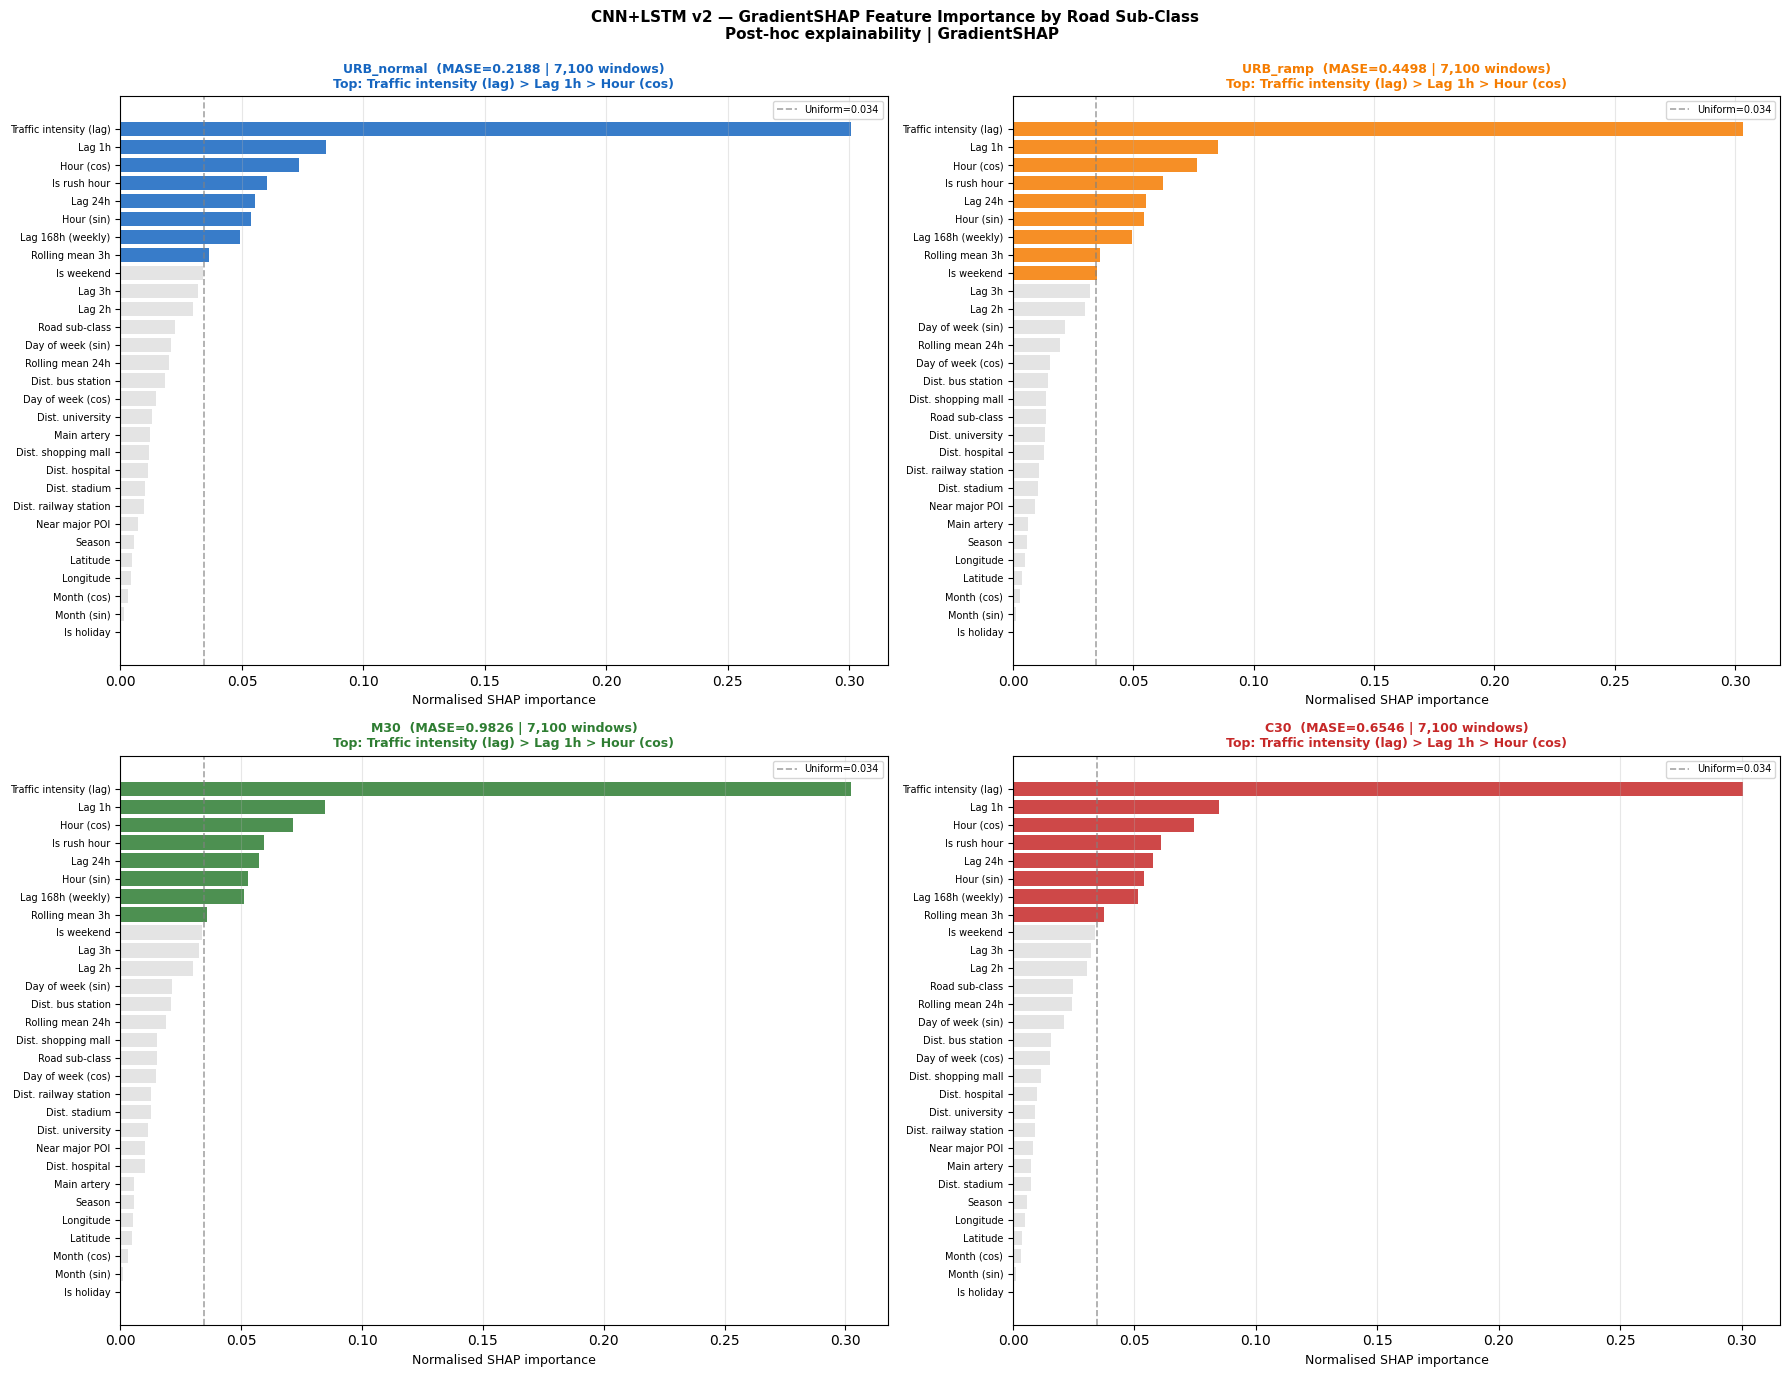

Saved: /home/iai-labor/traffic_project/explainability_figures/cnn_lstm_shap_subclass.png

Top 10 features — per sub-class SHAP comparison:
Feature                           URB_n    URB_r      M30      C30
------------------------------------------------------------
Traffic intensity (lag)          0.3007   0.3035   0.3023   0.3007
Lag 1h                           0.0845   0.0851   0.0847   0.0847
Hour (cos)                       0.0736   0.0766   0.0713   0.0745
Is rush hour                     0.0604   0.0623   0.0594   0.0610
Lag 24h                          0.0554   0.0552   0.0573   0.0575
Hour (sin)                       0.0538   0.0544   0.0526   0.0540
Lag 168h (weekly)                0.0490   0.0495   0.0512   0.0513
Rolling mean 3h                  0.0365   0.0363   0.0360   0.0373
Is weekend                       0.0338   0.0351   0.0338   0.0339
Lag 3h                           0.0321   0.0320   0.0325   0.0322


In [7]:
# ── Per sub-class SHAP importance ─────────────────────────────────────────────

print("Computing per sub-class SHAP importance...")

subclass_shap = {}

for enc, name in SUBCLASS_NAMES.items():
    # Find windows belonging to this sub-class
    class_mask = np.array([
        sensor_to_class.get(sid, -1) == enc
        for sid in shap_sensor_ids
    ])

    if class_mask.sum() == 0:
        print(f"  {name}: no windows — skipping")
        continue

    # Sub-class SHAP: mean absolute attribution per feature
    sc_attrs  = shap_per_window[class_mask]   # (n_sc_windows, 29)
    sc_mean   = sc_attrs.mean(axis=0)         # (29,)
    sc_norm   = sc_mean / sc_mean.sum()       # normalised

    subclass_shap[name] = {
        "raw":        sc_mean,
        "normalised": sc_norm,
        "n_windows":  int(class_mask.sum()),
    }
    print(f"  {name}: {class_mask.sum():,} windows | "
          f"top feature: {FEATURE_LABELS[np.argmax(sc_norm)]}")

print("\nPer sub-class analysis complete")

# ── Figure: per sub-class SHAP importance ─────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle(
    "CNN+LSTM v2 — GradientSHAP Feature Importance by Road Sub-Class\n"
    "Post-hoc explainability | GradientSHAP \n",
    fontsize=11, fontweight="bold"
)

MASE_VALS = {
    "URB_normal": 0.2188,
    "URB_ramp":   0.4498,
    "M30":        0.9826,
    "C30":        0.6546,
}

for ax, (name, color) in zip(
    axes.flat,
    [("URB_normal","#1565C0"), ("URB_ramp","#F57C00"),
     ("M30","#2E7D32"), ("C30","#C62828")]
):
    if name not in subclass_shap:
        ax.set_title(f"{name} — no data")
        continue

    sc_norm   = subclass_shap[name]["normalised"]
    sc_order  = np.argsort(sc_norm)
    labels_sc = [FEATURE_LABELS[i] for i in sc_order]
    vals_sc   = sc_norm[sc_order]
    uniform   = 1.0 / N_FEATURES

    bar_colors = [color if v >= uniform else "#E0E0E0"
                  for v in vals_sc]
    ax.barh(range(len(labels_sc)), vals_sc,
            color=bar_colors, alpha=0.85)
    ax.set_yticks(range(len(labels_sc)))
    ax.set_yticklabels(labels_sc, fontsize=7)
    ax.set_xlabel("Normalised SHAP importance", fontsize=9)
    ax.axvline(x=uniform, color="gray", linestyle="--",
               linewidth=1.2, alpha=0.7,
               label=f"Uniform={uniform:.3f}")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3, axis="x")

    top3 = [
        FEATURE_LABELS[i]
        for i in reversed(np.argsort(sc_norm)[-3:])
    ]
    n_windows = subclass_shap[name]["n_windows"]
    ax.set_title(
        f"{name}  (MASE={MASE_VALS[name]:.4f} | "
        f"{n_windows:,} windows)\n"
        f"Top: {' > '.join(top3)}",
        fontsize=9, fontweight="bold", color=color
    )

plt.tight_layout()
fig_path = os.path.join(
    FIGURES_DIR, "cnn_lstm_shap_subclass.png"
)
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Sub-class comparison table ─────────────────────────────────────────────────
print("\nTop 10 features — per sub-class SHAP comparison:")
print(f"{'Feature':<30} {'URB_n':>8} {'URB_r':>8} "
      f"{'M30':>8} {'C30':>8}")
print("-" * 60)

top10_overall = list(np.argsort(shap_norm)[::-1][:10])
for i in top10_overall:
    label = FEATURE_LABELS[i]
    vals  = [
        subclass_shap.get(sc, {}).get(
            "normalised", np.zeros(N_FEATURES)
        )[i]
        for sc in ["URB_normal","URB_ramp","M30","C30"]
    ]
    print(f"{label:<30} "
          + " ".join(f"{v:>8.4f}" for v in vals))

Shared features for comparison: 18


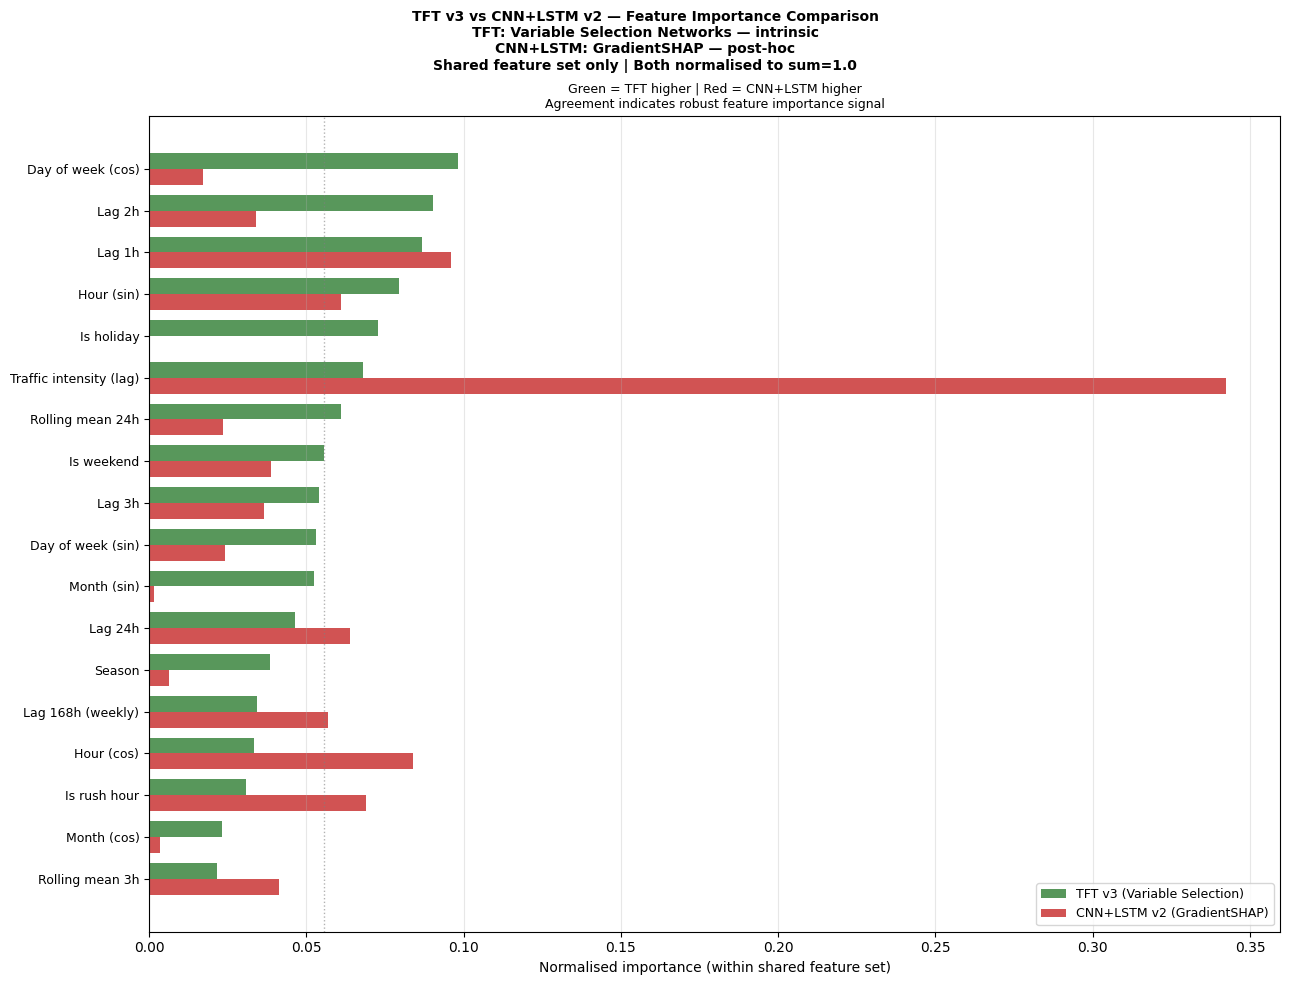

Saved: /home/iai-labor/traffic_project/explainability_figures/tft_vs_cnn_importance_comparison.png

TFT vs CNN+LSTM importance comparison (shared features):
Feature                             TFT      CNN  Ratio CNN/TFT    Agreement
----------------------------------------------------------------------------
Lag 1h                           0.0868   0.0961           1.11      ✓ agree
Lag 2h                           0.0904   0.0341           0.38     ✗ differ
Lag 3h                           0.0541   0.0365           0.67      ✓ agree
Lag 24h                          0.0465   0.0639           1.37      ✓ agree
Lag 168h (weekly)                0.0343   0.0570           1.66      ✓ agree
Rolling mean 3h                  0.0215   0.0414           1.93      ✓ agree
Rolling mean 24h                 0.0609   0.0235           0.38     ✗ differ
Traffic intensity (lag)          0.0680   0.3424           5.03     ✗ differ
Hour (sin)                       0.0796   0.0609           0.77      ✓ ag

In [8]:
# ── TFT vs CNN+LSTM feature importance comparison ─────────────────────────────
# Load TFT encoder importance from saved JSON for direct comparison
tft_json_path = os.path.join(
    FIGURES_DIR, "tft_v3_interpretation_results.json"
)
with open(tft_json_path) as f:
    tft_results = json.load(f)

# TFT encoder variable importance — normalised
tft_encoder = tft_results["overall"]["encoder"]

# Features that exist in BOTH models — the comparable set
# TFT encoder has: lag features + calendar features + relative_time_idx
# CNN+LSTM has: all 29 features including static
# For comparison: use features present in both
SHARED_FEATURES = {
    "lag_1h_norm":          "Lag 1h",
    "lag_2h_norm":          "Lag 2h",
    "lag_3h_norm":          "Lag 3h",
    "lag_24h_norm":         "Lag 24h",
    "lag_168h_norm":        "Lag 168h (weekly)",
    "roll_mean_3h_norm":    "Rolling mean 3h",
    "roll_mean_24h_norm":   "Rolling mean 24h",
    "target_norm":          "Traffic intensity (lag)",
    "hour_sin":             "Hour (sin)",
    "hour_cos":             "Hour (cos)",
    "dow_sin":              "Day of week (sin)",
    "dow_cos":              "Day of week (cos)",
    "month_sin":            "Month (sin)",
    "month_cos":            "Month (cos)",
    "is_weekend":           "Is weekend",
    "is_holiday":           "Is holiday",
    "is_rush_hour":         "Is rush hour",
    "season":               "Season",
}

# Extract TFT encoder importance for shared features
tft_shared = {}
for feat_key, label in SHARED_FEATURES.items():
    if feat_key in tft_encoder:
        tft_shared[label] = tft_encoder[feat_key]

# Extract CNN+LSTM SHAP importance for shared features
cnn_shared = {}
for feat_key, label in SHARED_FEATURES.items():
    if feat_key in FEATURE_COLS:
        idx = FEATURE_COLS.index(feat_key)
        cnn_shared[label] = float(shap_norm[idx])

# Renormalise both to sum=1.0 within shared feature set
tft_vals_raw = np.array([tft_shared[l] for l in SHARED_FEATURES.values()
                          if l in tft_shared])
cnn_vals_raw = np.array([cnn_shared[l] for l in SHARED_FEATURES.values()
                          if l in cnn_shared])

shared_labels = [l for l in SHARED_FEATURES.values()
                 if l in tft_shared and l in cnn_shared]
tft_vals = tft_vals_raw / tft_vals_raw.sum()
cnn_vals = cnn_vals_raw / cnn_vals_raw.sum()

print(f"Shared features for comparison: {len(shared_labels)}")

# ── Side-by-side comparison figure ────────────────────────────────────────────
order       = np.argsort(tft_vals)  # sort by TFT importance
labels_ord  = [shared_labels[i] for i in order]
tft_ord     = tft_vals[order]
cnn_ord     = cnn_vals[order]
x           = np.arange(len(labels_ord))
width       = 0.38

fig, ax = plt.subplots(figsize=(13, 10))
fig.suptitle(
    "TFT v3 vs CNN+LSTM v2 — Feature Importance Comparison\n"
    "TFT: Variable Selection Networks — intrinsic\n"
    "CNN+LSTM: GradientSHAP — post-hoc\n"
    "Shared feature set only | Both normalised to sum=1.0",
    fontsize=10, fontweight="bold"
)

bars_tft = ax.barh(x + width/2, tft_ord, width,
                   color="#2E7D32", alpha=0.80,
                   label="TFT v3 (Variable Selection)")
bars_cnn = ax.barh(x - width/2, cnn_ord, width,
                   color="#C62828", alpha=0.80,
                   label="CNN+LSTM v2 (GradientSHAP)")

ax.set_yticks(x)
ax.set_yticklabels(labels_ord, fontsize=9)
ax.set_xlabel("Normalised importance (within shared feature set)",
              fontsize=10)
ax.set_title(
    "Green = TFT higher | Red = CNN+LSTM higher\n"
    "Agreement indicates robust feature importance signal",
    fontsize=9
)
ax.legend(fontsize=9, loc="lower right")
ax.grid(True, alpha=0.3, axis="x")
ax.axvline(x=1/len(shared_labels), color="gray",
           linestyle=":", linewidth=1.0, alpha=0.6,
           label=f"Uniform={1/len(shared_labels):.3f}")

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "tft_vs_cnn_importance_comparison.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Agreement table ────────────────────────────────────────────────────────────
print("\nTFT vs CNN+LSTM importance comparison (shared features):")
print(f"{'Feature':<30} {'TFT':>8} {'CNN':>8} "
      f"{'Ratio CNN/TFT':>14} {'Agreement':>12}")
print("-" * 76)

for label, t, c in zip(
    shared_labels,
    tft_vals,
    cnn_vals
):
    ratio  = c / t if t > 1e-6 else float("nan")
    agree  = "✓ agree" if 0.5 <= ratio <= 2.0 else "✗ differ"
    print(f"{label:<30} {t:>8.4f} {c:>8.4f} "
          f"{ratio:>14.2f} {agree:>12}")

# ── Save all SHAP results ──────────────────────────────────────────────────────
shap_results = {
    "model":       "CNN+LSTM v2",
    "method":      "GradientSHAP — Lundberg & Lee (2017)",
    "n_windows":   len(shap_X),
    "n_samples":   N_SAMPLES,
    "batch_size":  SHAP_BATCH,
    "overall": {
        FEATURE_LABELS[i]: float(shap_norm[i])
        for i in range(N_FEATURES)
    },
    "per_subclass": {
        name: {
            FEATURE_LABELS[i]: float(
                subclass_shap[name]["normalised"][i]
            )
            for i in range(N_FEATURES)
        }
        for name in subclass_shap
    },
    "tft_comparison": {
        label: {
            "tft_weight":  float(t),
            "cnn_shap":    float(c),
            "ratio_cnn_tft": float(c/t) if t > 1e-6 else None,
        }
        for label, t, c in zip(shared_labels, tft_vals, cnn_vals)
    },
}

save_path = os.path.join(FIGURES_DIR, "cnn_lstm_shap_results.json")
with open(save_path, "w") as f:
    json.dump(shap_results, f, indent=2)
print(f"\nResults saved: {save_path}")

# ── Final figure checklist ─────────────────────────────────────────────────────
print("\nAll figures:")
for fname in [
    "cnn_lstm_shap_overall.png",
    "cnn_lstm_shap_subclass.png",
    "tft_vs_cnn_importance_comparison.png",
]:
    fpath  = os.path.join(FIGURES_DIR, fname)
    exists = "✓" if os.path.exists(fpath) else "✗ MISSING"
    print(f"  {exists}  {fname}")

print("\n✓ shap_cnn_lstm.ipynb complete")

Peak windows (weekday 06-09, 17-20):   6,400
Valley windows (weekday 22-05):         6,500

Mean signed attribution across peak windows:
  Traffic intensity (lag)         +0.0089  ↑ pushes up
  Lag 1h                          -0.0019  ↓ pushes down
  Hour (cos)                      -0.0010  ↓ pushes down
  Lag 24h                         +0.0010  ↑ pushes up
  Is rush hour                    +0.0008  ↑ pushes up
  Is weekend                      +0.0006  ↑ pushes up
  Hour (sin)                      +0.0006  ↑ pushes up
  Lag 168h (weekly)               +0.0005  ↑ pushes up
  Day of week (sin)               +0.0005  ↑ pushes up
  Lag 2h                          -0.0003  ↓ pushes down

Mean signed attribution across valley windows:
  Traffic intensity (lag)         -0.0189  ↓ pushes down
  Lag 1h                          +0.0047  ↑ pushes up
  Hour (cos)                      +0.0032  ↑ pushes up
  Lag 168h (weekly)               -0.0022  ↓ pushes down
  Lag 24h                         -

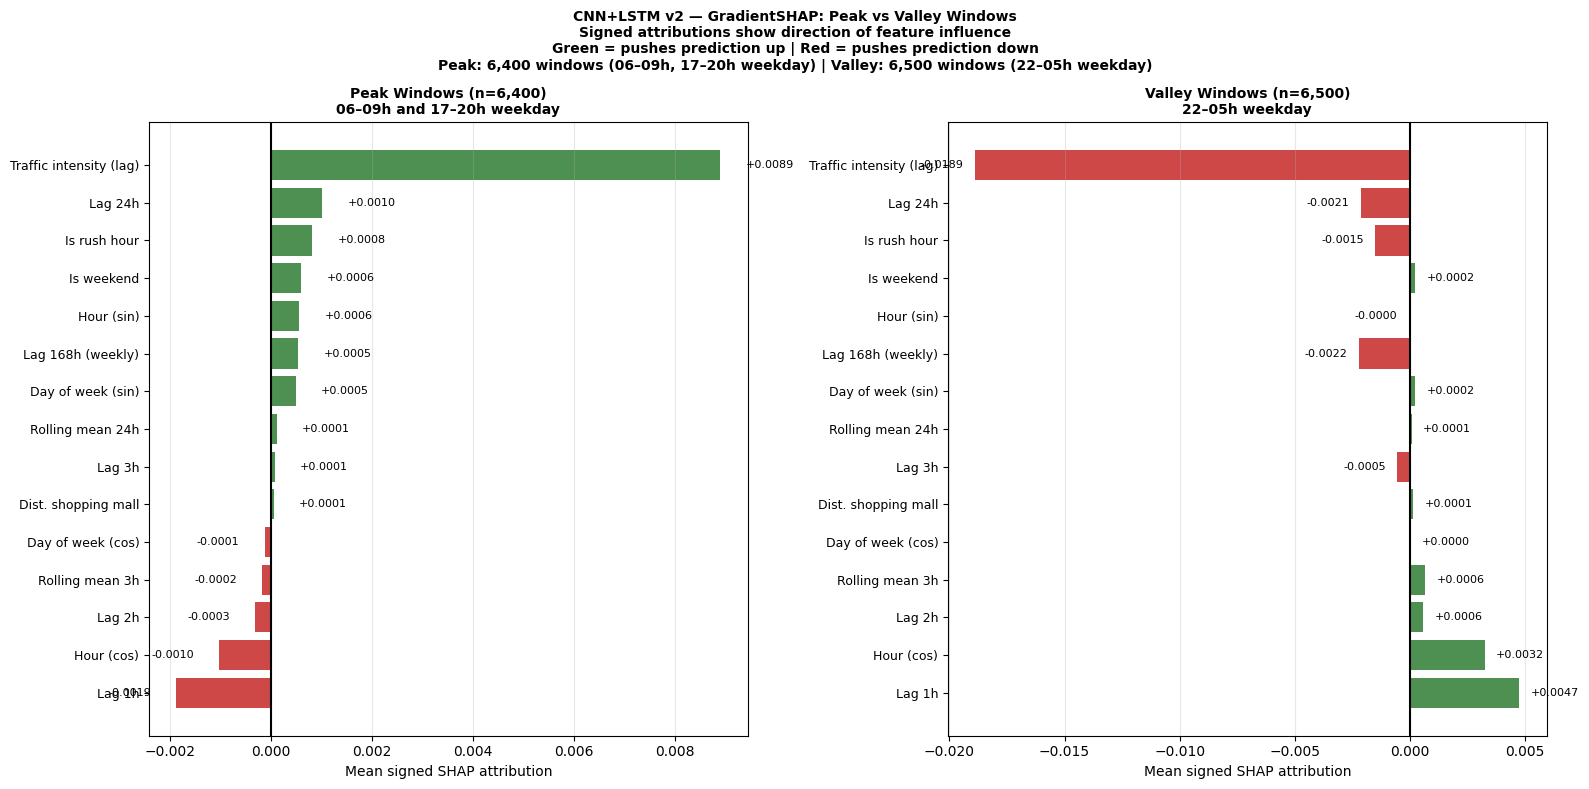

Saved: /home/iai-labor/traffic_project/explainability_figures/cnn_lstm_shap_peak_valley.png

Peak vs Valley — top features by difference:
Feature                             Peak    Valley   Difference       Interpretation
-------------------------------------------------------------------------------------
Traffic intensity (lag)          +0.0089   -0.0189      +0.0278  more positive at peak
Lag 1h                           -0.0019   +0.0047      -0.0066  more negative at peak
Hour (cos)                       -0.0010   +0.0032      -0.0043  more negative at peak
Lag 24h                          +0.0010   -0.0021      +0.0031  more positive at peak
Lag 168h (weekly)                +0.0005   -0.0022      +0.0028  more positive at peak
Is rush hour                     +0.0008   -0.0015      +0.0023  more positive at peak
Lag 2h                           -0.0003   +0.0006      -0.0009  similar both periods
Rolling mean 3h                  -0.0002   +0.0006      -0.0008  similar both perio

In [9]:
# ── Peak vs Valley signed SHAP analysis ───────────────────────────

# ── Reconstruct timestamps for shap windows ────────────────────────────────────
shap_timestamps = pd.to_datetime([
    time_origin + pd.Timedelta(hours=int(shap_dataset.t_starts[i]))
    for i in range(len(shap_dataset))
])

shap_hours = shap_timestamps.hour
shap_dow   = shap_timestamps.dayofweek

# Define peak and valley masks
morning_mask  = (shap_hours >= 6)  & (shap_hours <= 9)
evening_mask  = (shap_hours >= 17) & (shap_hours <= 20)
peak_mask     = morning_mask | evening_mask
valley_mask   = (shap_hours >= 22) | (shap_hours <= 5)
weekday_mask  = shap_dow < 5

peak_idx   = np.where(peak_mask   & weekday_mask)[0]
valley_idx = np.where(valley_mask & weekday_mask)[0]

print(f"Peak windows (weekday 06-09, 17-20):   {len(peak_idx):,}")
print(f"Valley windows (weekday 22-05):         {len(valley_idx):,}")

# ── Signed SHAP attributions for peak and valley ───────────────────────────────
# Use signed (not absolute) attributions to show direction
# (48, 29) → mean across timesteps → (29,) per window

# Peak: mean signed attribution per feature
peak_signed   = shap_attrs[peak_idx].mean(axis=1)    # (n_peak, 29)
valley_signed = shap_attrs[valley_idx].mean(axis=1)  # (n_valley, 29)

peak_mean   = peak_signed.mean(axis=0)    # (29,)
valley_mean = valley_signed.mean(axis=0)  # (29,)

print(f"\nMean signed attribution across peak windows:")
top_peak = np.argsort(np.abs(peak_mean))[::-1][:10]
for i in top_peak:
    direction = "↑ pushes up" if peak_mean[i] > 0 else "↓ pushes down"
    print(f"  {FEATURE_LABELS[i]:<30} {peak_mean[i]:>+8.4f}  {direction}")

print(f"\nMean signed attribution across valley windows:")
top_valley = np.argsort(np.abs(valley_mean))[::-1][:10]
for i in top_valley:
    direction = "↑ pushes up" if valley_mean[i] > 0 else "↓ pushes down"
    print(f"  {FEATURE_LABELS[i]:<30} {valley_mean[i]:>+8.4f}  {direction}")

# ── Figure: Peak vs Valley signed SHAP ────────────────────────────────────────
# Show top 15 features by absolute importance
# Side by side: peak (left) vs valley (right)
# Colour by direction: green = positive, red = negative

top15_idx = np.argsort(
    np.abs(peak_mean) + np.abs(valley_mean)
)[::-1][:15]

top15_labels = [FEATURE_LABELS[i] for i in top15_idx]
peak_top15   = peak_mean[top15_idx]
valley_top15 = valley_mean[top15_idx]

# Sort by peak importance for consistent ordering
sort_order   = np.argsort(peak_top15)
top15_labels = [top15_labels[i] for i in sort_order]
peak_top15   = peak_top15[sort_order]
valley_top15 = valley_top15[sort_order]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle(
    "CNN+LSTM v2 — GradientSHAP: Peak vs Valley Windows\n"
    "Signed attributions show direction of feature influence\n"
    "Green = pushes prediction up | Red = pushes prediction down\n"
    f"Peak: {len(peak_idx):,} windows (06–09h, 17–20h weekday) | "
    f"Valley: {len(valley_idx):,} windows (22–05h weekday)",
    fontsize=10, fontweight="bold"
)

def plot_signed_shap(ax, labels, values, title):
    colors = ["#2E7D32" if v > 0 else "#C62828" for v in values]
    ax.barh(range(len(labels)), values, color=colors, alpha=0.85)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=9)
    ax.axvline(x=0, color="black", linewidth=1.5)
    ax.set_xlabel("Mean signed SHAP attribution", fontsize=10)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.grid(True, alpha=0.3, axis="x")
    for i, val in enumerate(values):
        offset = 0.0005 if val >= 0 else -0.0005
        ha     = "left"  if val >= 0 else "right"
        ax.text(val + offset, i, f"{val:+.4f}",
                va="center", ha=ha, fontsize=8)

plot_signed_shap(
    axes[0], top15_labels, peak_top15,
    f"Peak Windows (n={len(peak_idx):,})\n"
    f"06–09h and 17–20h weekday"
)
plot_signed_shap(
    axes[1], top15_labels, valley_top15,
    f"Valley Windows (n={len(valley_idx):,})\n"
    f"22–05h weekday"
)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "cnn_lstm_shap_peak_valley.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Difference table: peak vs valley ──────────────────────────────────────────
print("\nPeak vs Valley — top features by difference:")
print(f"{'Feature':<30} {'Peak':>9} {'Valley':>9} "
      f"{'Difference':>12} {'Interpretation':>20}")
print("-" * 85)

diff = peak_mean - valley_mean
top_diff_idx = np.argsort(np.abs(diff))[::-1][:12]

for i in top_diff_idx:
    label  = FEATURE_LABELS[i]
    p_val  = peak_mean[i]
    v_val  = valley_mean[i]
    d_val  = diff[i]
    interp = (
        "more positive at peak"   if d_val > 0.001 else
        "more negative at peak"   if d_val < -0.001 else
        "similar both periods"
    )
    print(f"{label:<30} {p_val:>+9.4f} {v_val:>+9.4f} "
          f"{d_val:>+12.4f}  {interp}")

In [10]:
# ── Update saved results with peak/valley ─────────────────────────
# Reload and update the JSON with peak/valley signed results
save_path = os.path.join(FIGURES_DIR, "cnn_lstm_shap_results.json")
with open(save_path) as f:
    shap_results = json.load(f)

shap_results["peak_valley"] = {
    "peak_windows":   int(len(peak_idx)),
    "valley_windows": int(len(valley_idx)),
    "peak_signed": {
        FEATURE_LABELS[i]: float(peak_mean[i])
        for i in range(N_FEATURES)
    },
    "valley_signed": {
        FEATURE_LABELS[i]: float(valley_mean[i])
        for i in range(N_FEATURES)
    },
    "difference": {
        FEATURE_LABELS[i]: float(diff[i])
        for i in range(N_FEATURES)
    },
}

with open(save_path, "w") as f:
    json.dump(shap_results, f, indent=2)
print(f"Peak/valley results added to: {save_path}")

# ── Final figure checklist ─────────────────────────────────────────
print("\nAll 11b figures:")
for fname in [
    "cnn_lstm_shap_overall.png",
    "cnn_lstm_shap_subclass.png",
    "tft_vs_cnn_importance_comparison.png",
    "cnn_lstm_shap_peak_valley.png",
]:
    fpath  = os.path.join(FIGURES_DIR, fname)
    exists = "✓" if os.path.exists(fpath) else "✗ MISSING"
    print(f"  {exists}  {fname}")

print("\n✓ shap_cnn_lstm.ipynb complete")

Peak/valley results added to: /home/iai-labor/traffic_project/explainability_figures/cnn_lstm_shap_results.json

All 11b figures:
  ✓  cnn_lstm_shap_overall.png
  ✓  cnn_lstm_shap_subclass.png
  ✓  tft_vs_cnn_importance_comparison.png
  ✓  cnn_lstm_shap_peak_valley.png

✓ shap_cnn_lstm.ipynb complete
